Name: Trang Nguyen

ID: 1622316

In this project, I aim to build a machine learning system to predict employee churn based on HR data. The objective is to help organizations identify employees at risk of leaving so that timely retention strategies can be implemented.

I applied and evaluated 6 classification models commonly used for binary classification tasks:

1. Logistic Regression

2. Decision Tree

3. Random Forest

4. Gradient Boosting Classifier

5. Multilayer Perceptron (MLP)

6. Support Vector Machine (SVM)

I trained and evaluated each model using key performance metrics:

- Accuracy

- Precision

- Recall

- F1-score

- AUC (Area Under the ROC Curve)

I also visualized performance using confusion matrices and ROC curves to provide a clearer comparison between models.



Exploratory data analysis and visualization of employee churn dataset using matplotlib and seaborn, model building and evaluation using python scikit-learn package.

Predicting Employee Churn with Machine Learning (Colab)

Classification model trained on 14,999 employees

# **Description of the dataset**

The dataset contains 14,999 samples, and 9 attributes or features (6 integer, 2 float, and 2 objects), and 'left', the 'Target' variable  (what we want to predict).

The 10 variables are as follows:

1. satisfaction_level: employee satisfaction (0-1).  
2. last_evaluation: evaluated performance by the employer (0-1).
3. number_projects: numbers of projects assigned to an employee
4. average_monthly_hours: ave numbers of hours worked by an employee in a month
5. time_spent_company: employee experience measured as number of years in Co.
6. work_accident: Whether an employee has had a work accident
7. promotion_last_5years: promotion in the last 5 years
8. Departments: Employee's department
9. Salary: Salary level of the employee (low, medium and high).
10.left: 1 = employee left the Co. 0 = did not leave.

In [8]:
#import modules
import pandas as pd  # for dataframes manipulations
import matplotlib.pyplot as plt # for plotting graphs
import seaborn as sns # for plotting graphs
import numpy as np
#MODEL
from imblearn.over_sampling import SMOTE # will not use this yet
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

In [9]:
HRdf = pd.read_csv("/content/HR_Employee_churn.csv")

In [10]:
HRdf

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Departments,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [11]:
#check attributes names, null values and datatypes using info().
#dataset contains 14,999 instances, and 9 features and 1 target (6 integer, 2 float, and 2 objects).
#float32 is a 32 bit number - float64 uses 64 bits.
#That means that float64’s take up twice as much memory - and doing operations on them may be a lot slower in some machine architectures.
#However, float64’s can represent numbers much more accurately than 32 bit floats.

HRdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Departments            14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


In [12]:
HRdf.isnull().sum() # another way to count null values in dataset

,0
satisfaction_level,0
last_evaluation,0
number_project,0
average_montly_hours,0
time_spend_company,0
Work_accident,0
left,0
promotion_last_5years,0
Departments,0
salary,0


In this dataset, we have two types of employee, those who stayed and those that left the company. Compare their characteristics by group (the column 'left'). Here, you can find the average of both the groups using groupby() and mean() function.

In [13]:
# Calculate the mean of the 'left' column in the HRdf dataframe i.e. the churn rate
left_mean = HRdf['left'].mean()
print(left_mean)

0.2380825388359224


Use the 'describe()' function in pandas to get various summary statistics.

This function returns the count, mean, standard deviation, minimum and maximum values and the quantiles of the data (except 'Departments' and 'salary' are not in the output as they are not numeric but objects)

In [14]:
# The describe() function is a handy tool in the pandas library (which is imported as pandas in the code).
# It automatically calculates and provides summary statistics HRdf.describe().applymap(lambda x: f'{x:.2f}').T
HRdf.describe().applymap(lambda x: f'{x:.2f}')

<ipython-input-14-468c8ebba4f3>:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  HRdf.describe().applymap(lambda x: f'{x:.2f}')


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.00,14999.00,14999.00,14999.00,14999.00,14999.00,14999.00,14999.00
mean,0.61,0.72,3.80,201.05,3.50,0.14,0.24,0.02
std,0.25,0.17,1.23,49.94,1.46,0.35,0.43,0.14
min,0.09,0.36,2.00,96.00,2.00,0.00,0.00,0.00
25%,0.44,0.56,3.00,156.00,3.00,0.00,0.00,0.00
50%,0.64,0.72,4.00,200.00,3.00,0.00,0.00,0.00
75%,0.82,0.87,5.00,245.00,4.00,0.00,0.00,0.00
max,1.00,1.00,7.00,310.00,10.00,1.00,1.00,1.00


**Data Visualization**

Compare the number of employees that left the company 'left' = 1 and those that stayed 'left' = 0

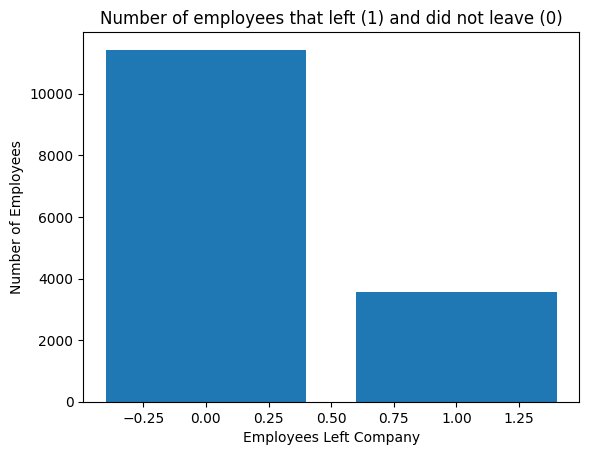

In [15]:
left_count=HRdf.groupby('left').count()
plt.bar(left_count.index.values, left_count['satisfaction_level'])
plt.title('Number of employees that left (1) and did not leave (0)')
plt.xlabel('Employees Left Company')
plt.ylabel('Number of Employees')
plt.show()

In [16]:
#Here, you can see that out of 15,000 approx 3,571 left ('left' column =1), and 11,428 stayed. The no of employee left is 23 % of the total employee.
HRdf.left.value_counts() # get a count of how many employees left and how many stayed.

,count
left,
0,11428
1,3571


In [17]:
#Here, you can see that out of 15,000 employees, approx 319  got a promotion within last 5 yrs. ('promotion_last_5years' column =1), and 14,680 did not get a promotion.
HRdf.promotion_last_5years.value_counts()

,count
promotion_last_5years,
0,14680
1,319


The percentage of employees who got a promotion is: 2.127%


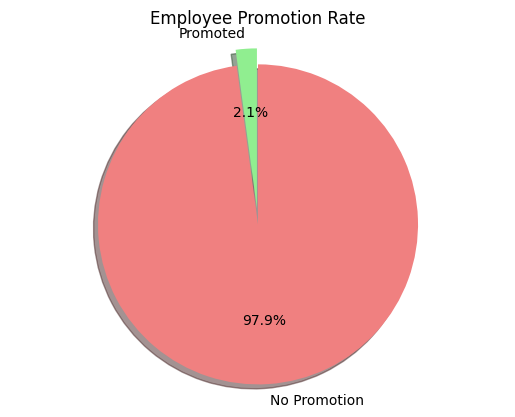

In [18]:
# # Calculate the percentage of employees who got a promotion
total_employees = len(HRdf) # First calculate the total number of employees

# Calculate the number of employees who got a promotion
promoted_employees = len(HRdf[HRdf['promotion_last_5years'] == 1])

# Calculate the percentage of employees who got a promotion
promotion_percentage = (promoted_employees / total_employees) * 100

# Data for the pie chart
labels = ['Promoted', 'No Promotion']
# Calculate 'no_promotion_percentage'
no_promotion_percentage = 100 - promotion_percentage
sizes = [promotion_percentage, no_promotion_percentage]
colors = ['lightgreen', 'lightcoral']  # Choose colors for the slices
explode = (0.1, 0)  # Explode the 'Promoted' slice

# # Calculate the percentage of employees who got a promotion
total_employees = len(HRdf) # First calculate the total number of employees

# Calculate the number of employees who got a promotion
promoted_employees = len(HRdf[HRdf['promotion_last_5years'] == 1])

# Calculate the percentage of employees who got a promotion
promotion_percentage = (promoted_employees / total_employees) * 100

print(f"The percentage of employees who got a promotion is: {promotion_percentage:.3f}%")
import matplotlib.pyplot as plt

# Data for the pie chart
labels = ['Promoted', 'No Promotion']
# Calculate 'no_promotion_percentage'
no_promotion_percentage = 100 - promotion_percentage
sizes = [promotion_percentage, no_promotion_percentage]
colors = ['lightgreen', 'lightcoral']  # colors for the slices
explode = (0.1, 0)  # Explode the 'Promoted' slice

# Create the pie chart
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        shadow=True, startangle=90)  # Add a shadow and start angle

plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

plt.title("Employee Promotion Rate")
plt.show()



Number of Projects

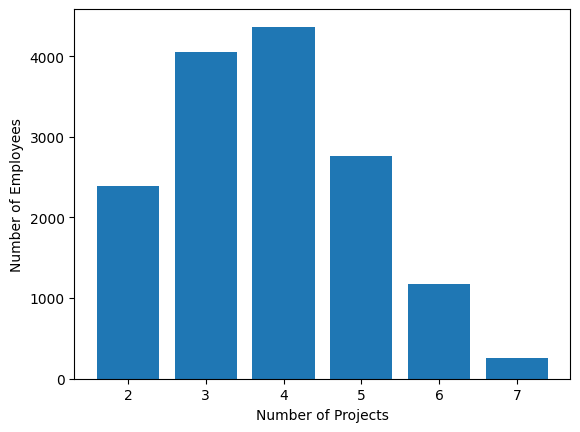

In [19]:
# bar chart to show the number of projects employees are involved in?

num_projects=HRdf.groupby('number_project').count()
plt.bar(num_projects.index.values, num_projects['satisfaction_level'])
plt.xlabel('Number of Projects')
plt.ylabel('Number of Employees')
plt.show()

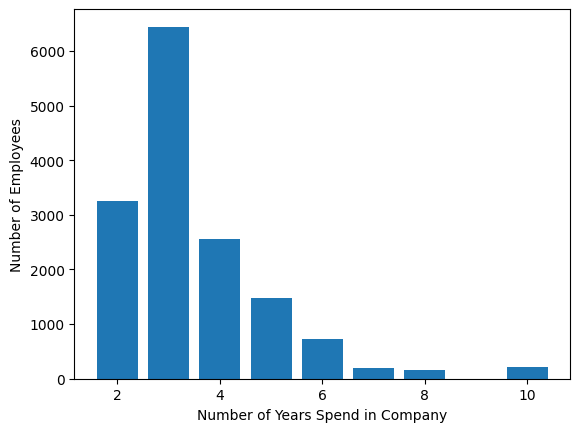

In [20]:
#Time Spent in Company ~ as an indicator of employee work experience
# bar chart to show the number of employees and their years of experience in the company?
time_spent=HRdf.groupby('time_spend_company').count()
plt.bar(time_spent.index.values, time_spent['satisfaction_level'])
plt.xlabel('Number of Years Spend in Company')
plt.ylabel('Number of Employees')
plt.show()


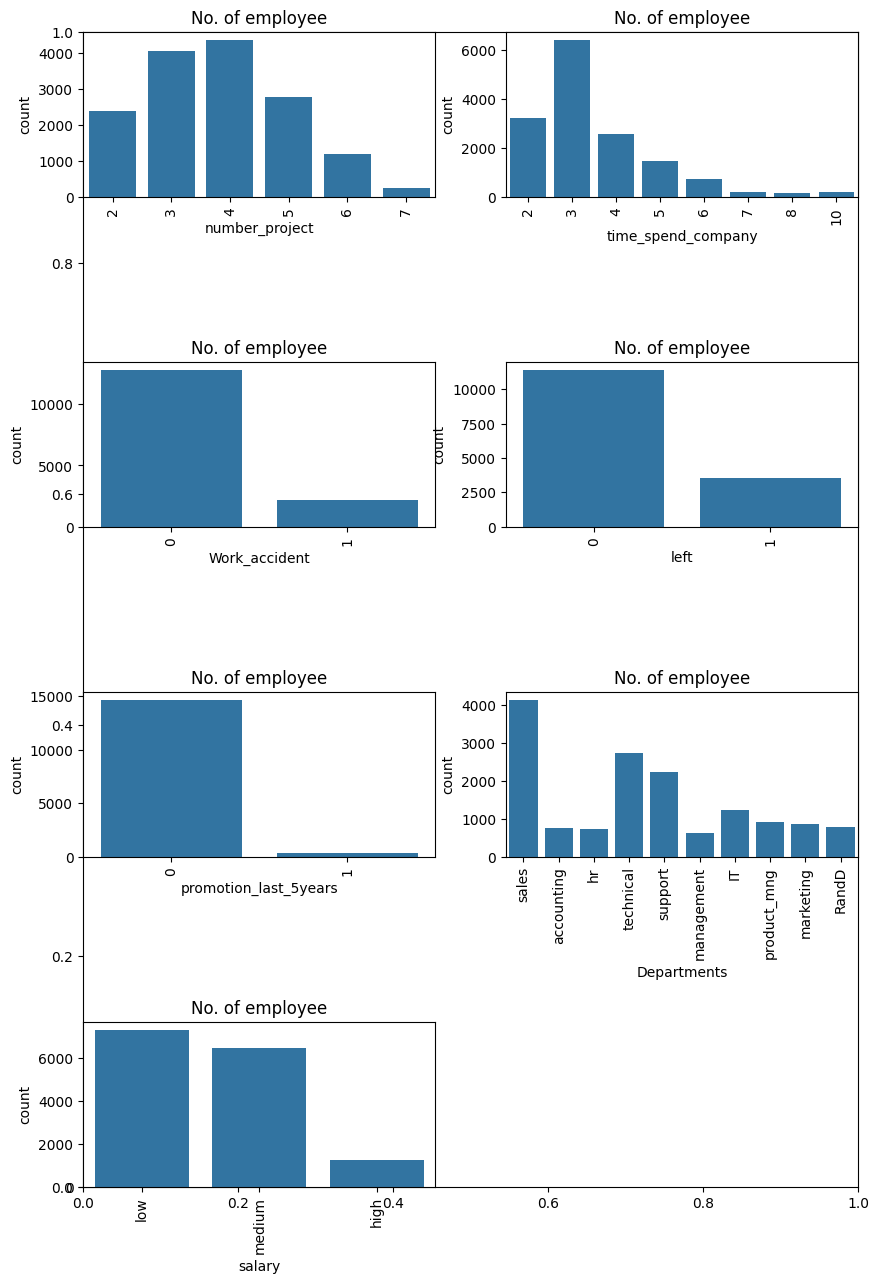

In [21]:
#Subplots using Seaborn library to plot all the graphs in a single cell.
features=['number_project','time_spend_company','Work_accident','left', 'promotion_last_5years','Departments','salary'] # Removed the extra space from 'Departments '
fig=plt.subplots(figsize=(10,15))
for i, j in enumerate(features):
    plt.subplot(4, 2, i+1)
    plt.subplots_adjust(hspace = 1.0)
    sns.countplot(x=j,data = HRdf)
    plt.xticks(rotation=90)
    plt.title("No. of employee")

From the above visualization:

Most of the employee were involved in 3-5 projects.

The highest number of employee have 3 years of experience then it tapers off.

The number of employee that quit is about [3571 / (11428+3571)] 23.8 %.

The number of employee promoted in the last 5 year is about [319 / (14680+319)] 2.1%

The sales department has the maximum no.of employee followed by technical and support

Most of the employees are earning in the medium or low salary range.

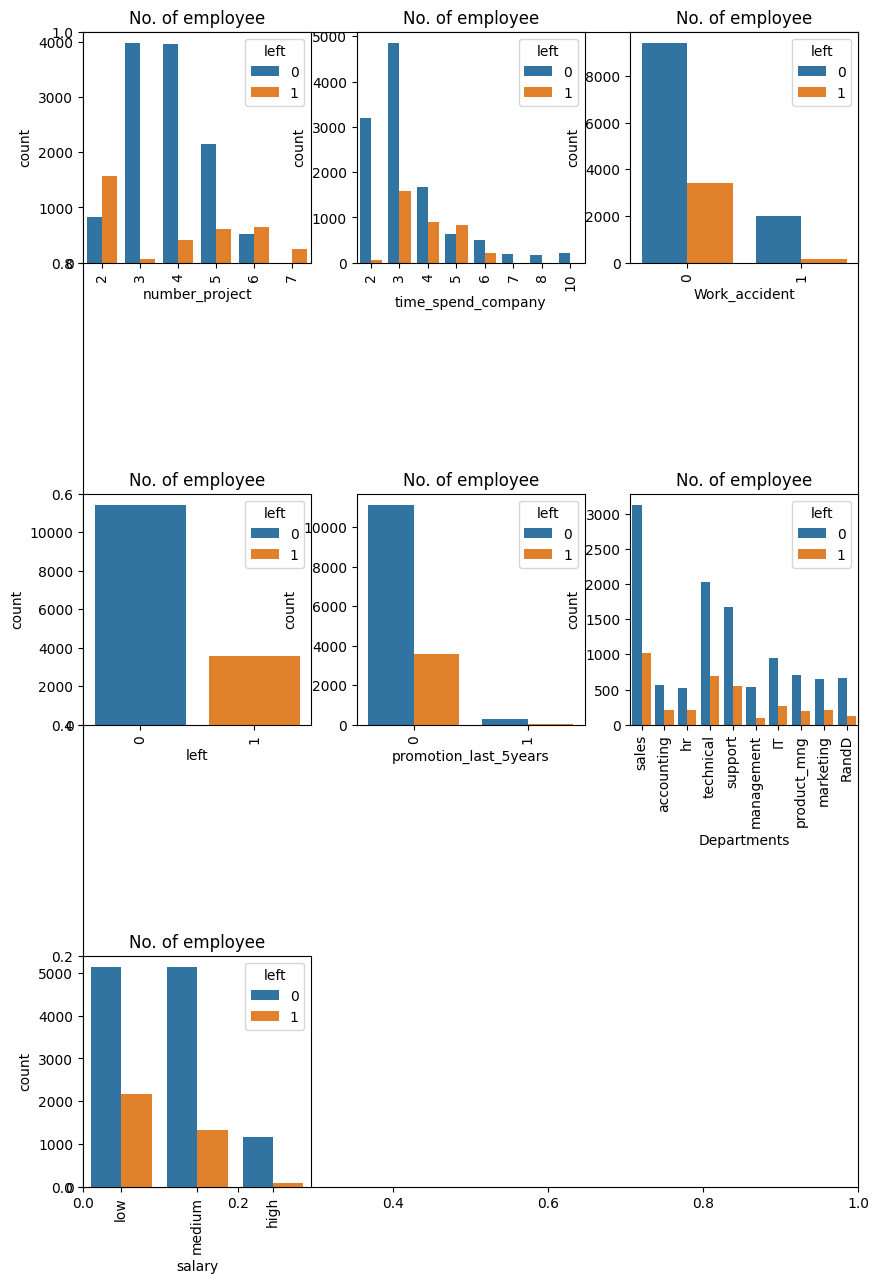

In [22]:
fig=plt.subplots(figsize=(10,15)) #Creates a figure (the overall container for the plots) and sets its size.
for i, j in enumerate(features): # the loop iterates through each feature in the features list
    plt.subplot(3, 3, i+1) # creates a subplot using plt.subplot(3, 3, i+1)
    plt.subplots_adjust(hspace = 1.0) #Adds spacing between the subplots to make them more readable.
    sns.countplot(x=j,data = HRdf, hue='left')
    plt.xticks(rotation=90)
    plt.title("No. of employee")

You can observe the following points in the above visualization:

Those employees who are involved in more than 5 projects leave the company.

The employee who had done 6 and 7 projects, over worked, tend to leave.

Most employee leave after 3 to 5 years at the company.

Employees that had a promotion in the last 5 years tend to stay, i.e., all those left they didn't get the promotion in the last 5 years.

Data Analysis and Visualization Summary:

The features that most influence a person to leave the company:

Promotions: Employees are far more likely to quit their job if they did not get promoted in the last 5 years.

Time with Company: The three-year mark looks like a critical point in an employee's career. Most of them quit their job around the three-year mark. Another important point is 6-years point, where the employee is very unlikely to leave.

Number Of Projects: Employee engagement is another critical factor to influence the employee to quit. Employees with 3-5 projects are less likely to leave the company.

Salary: Most of the employees that quit are among the low salary category.

Building a Prediction Model

Pre-Processing Data
Lots of machine learning algorithms require numerical input data, so you need to represent categorical columns in a numerical column. In order to encode this data, you could map each value to a number. e.g. Salary column's value can be represented as low:0, medium:1, and high:2. This process is known as label encoding, and sklearn conveniently will do this for you using LabelEncoder.

In [23]:
HRdf # see 'Departments' & 'salary' columns.

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Departments,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [25]:
n = HRdf.nunique(axis=0) # unique values of each column in the dataframe HRdf ~ there are 10 unique departments and 3 unique salary grouping
n

,0
satisfaction_level,92
last_evaluation,65
number_project,6
average_montly_hours,215
time_spend_company,8
Work_accident,2
left,2
promotion_last_5years,2
Departments,10
salary,3


In [26]:
#import preprocessing module and created Label Encoder object to fit and transform "salary" and "Departments " columns into numeric column.
# there are 3 levels of 'Salary' ~ "Low", "Medium" & "High"
# There are 10 'Department' ~ "accounting","hr","IT","management","marketing","product_mng","RandD","sales",suppport",& "technical"
# Import LabelEncoder
from sklearn import preprocessing
#creating labelEncoder
le = preprocessing.LabelEncoder()
# Converting string labels into numbers.
HRdf['salary']=le.fit_transform(HRdf['salary'])
# Access the 'Departments' column (without the extra space)
HRdf['Departments']=le.fit_transform(HRdf['Departments']) # Changed 'Departments ' to 'Departments'

In [27]:
# Look at the 'Department' and the 'salary ' columnafter the transformation
HRdf


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Departments,salary
0,0.38,0.53,2,157,3,0,1,0,7,1
1,0.80,0.86,5,262,6,0,1,0,7,2
2,0.11,0.88,7,272,4,0,1,0,7,2
3,0.72,0.87,5,223,5,0,1,0,7,1
4,0.37,0.52,2,159,3,0,1,0,7,1
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,8,1
14995,0.37,0.48,2,160,3,0,1,0,8,1
14996,0.37,0.53,2,143,3,0,1,0,8,1
14997,0.11,0.96,6,280,4,0,1,0,8,1


Split the dataframe into Training and Testing Set using sklearn

train_test_split is a function in Sklearn model selection for splitting data arrays into two subsets: for training data and for testing data. With this function, you don't need to divide the dataset manually.

By default, Sklearn train_test_split will make random partitions for the two subsets. However, you can also specify a random state for the operation.

Divide the dataset into training and testing set by splitting the HRdf dataset using the function "train_test_split()" function.

3 parameters are needed as input to the function: features, target, and test_set size, typically 25 to 30% for testing.

Use random_state to select records randomly.

In [28]:
# create the X and y variable array
X=HRdf[['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident',
       'promotion_last_5years', 'Departments', 'salary']]  # Changed 'Departments ' to 'Departments'
# or just drop the 'left' variable like previous assignments
#HRdf. drop('left', axis=1, inplace=True)
y=HRdf['left'] # the target variable is the 'left' variable ~ put column into 'y'

In [29]:
X

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,Departments,salary
0,0.38,0.53,2,157,3,0,0,7,1
1,0.80,0.86,5,262,6,0,0,7,2
2,0.11,0.88,7,272,4,0,0,7,2
3,0.72,0.87,5,223,5,0,0,7,1
4,0.37,0.52,2,159,3,0,0,7,1
...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,0,8,1
14995,0.37,0.48,2,160,3,0,0,8,1
14996,0.37,0.53,2,143,3,0,0,8,1
14997,0.11,0.96,6,280,4,0,0,8,1


In [30]:
y

,left
0,1
1,1
2,1
3,1
4,1
...,...
14994,1
14995,1
14996,1
14997,1


In [33]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)  # 70% of the dataset is used for training and 30% test

In [34]:
X_test

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,Departments,salary
6723,0.65,0.96,5,226,2,1,0,5,2
6473,0.88,0.80,3,166,2,0,0,0,1
4679,0.69,0.98,3,214,2,0,0,7,1
862,0.41,0.47,2,154,3,0,0,7,1
7286,0.87,0.76,5,254,2,1,0,3,1
...,...,...,...,...,...,...,...,...,...
13388,0.85,0.81,4,260,3,0,0,6,2
10463,0.21,0.43,2,249,3,0,0,5,1
5331,0.78,0.53,3,156,3,0,0,6,1
7499,0.93,0.58,5,238,2,0,0,7,2


**Model Building**

**There are a number of classification models:**
1.   logistic regression
2.   decision tree
1.   random forest
1.   gradient-boosted tree
2.   multilayer perceptron
2.   one-vs-rest (mainly for multiple class)
1.   Naive Bayes
1.   Support Vector Machine (SVM)





To use the various Classifier.
First, import the Classifier module and create classifier object using Classifier() function.
Then, fit your model on training set using fit() and perform prediction on the test set using predict().

***1. Logistic Regression***

Logistic Regression to predict churn. First, import the Logistic Regression module and create Logistic Regression object using LogisticRegression(solver='lbfgs', max_iter=1000) function. Then, fit your model on train set using fit() and perform prediction on the test set using predict().

In [35]:
# Use Logistic Regression to predict
# Import the Scikit Learn Logistic Regression module
from sklearn.linear_model import LogisticRegression

#Create an instance of Logistic regression Classifier
lr = LogisticRegression(solver='lbfgs', max_iter=1000)

#Train the model using the training sets
lr.fit(X_train,y_train)

#Predict the response for test dataset
lry_pred = lr.predict(X_test)

Evaluating Model Performance of the model with the test dataset "y_test"

In [36]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, lry_pred))
# Model Precision
print("Precision:",metrics.precision_score(y_test, lry_pred))
# Model Recall
print("Recall:",metrics.recall_score(y_test, lry_pred))
# Calculate F1 score
f1 = metrics.f1_score(y_test, lry_pred)
print("F1 score:",metrics.f1_score(y_test, lry_pred))

Accuracy: 0.7602222222222222
Precision: 0.4932301740812379
Recall: 0.23787313432835822
F1 score: 0.3209565764631844


The most frequently used performance metrics for classification:

*Accuracy*

*Precision*

*Specificity*

*F-score*

From the logistic regression output:

TP = 103; FN

FP = 0   ; TN

*Accuracy* = (TP + TN) / (TP + FP + TN + FN)  

*Precision* = TP / (TP + FP)
         
*Recall* = TP / (TP + FN)
             
*Specifity* = TN / (TN + FP)
            
*F-score* = (2 x Precision x Recall) / (Precision + Recall)
          


**Calculating the the Precision, Recall, and F Score**


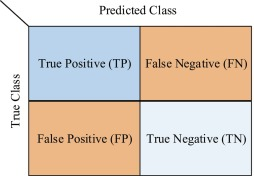

**Evaluating Model Performance**

Accuracy: Accuracy (classification) rate of 97% (Gradient Boosting Classifier), 76%  (Logistic Regression).

Precision:
Precision is about being precise, i.e., how precise your model is. In other words, you can say, when a model makes a prediction, how often it is correct. In your prediction case, when you predicted an employee is going to leave, that employee actually left 95% (Gradient Boosting model), 49% (Logistic Regression) of the time.

Recall: If there is an employee who left present in the test set and your model can identify it 92% (Gradient Boosting), 23% (Logistic Regression) of the time.
So which model is the better of the two?


In [37]:
from sklearn.metrics import classification_report, confusion_matrix
import itertools
def plot_confusion_matrix(cm, classes,
                          normalize=True,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True` above.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
print(confusion_matrix(y_test, lry_pred, labels=[1,0]))

[[ 255  817]
 [ 262 3166]]


In [38]:
# Compute confusion matrix
cnf_matrix = confusion_matrix(y_test, lry_pred, labels=[1,0])
np.set_printoptions(precision=2)

Confusion matrix, without normalization
[[ 255  817]
 [ 262 3166]]


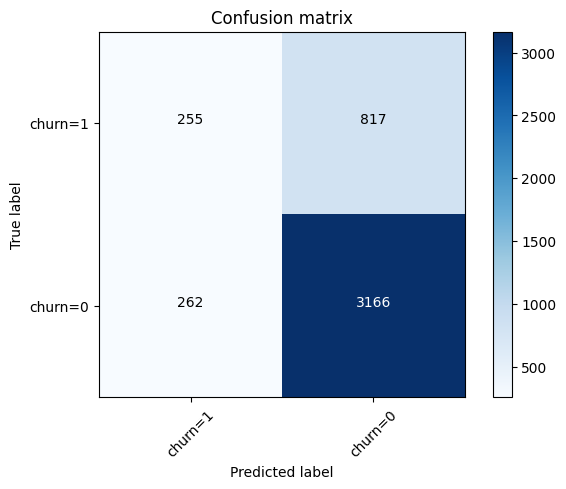

In [39]:
#Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=['churn=1','churn=0'],normalize= False,  title='Confusion matrix')

In [40]:
print (classification_report(y_test, lry_pred))

              precision    recall  f1-score   support

           0       0.79      0.92      0.85      3428
           1       0.49      0.24      0.32      1072

    accuracy                           0.76      4500
   macro avg       0.64      0.58      0.59      4500
weighted avg       0.72      0.76      0.73      4500



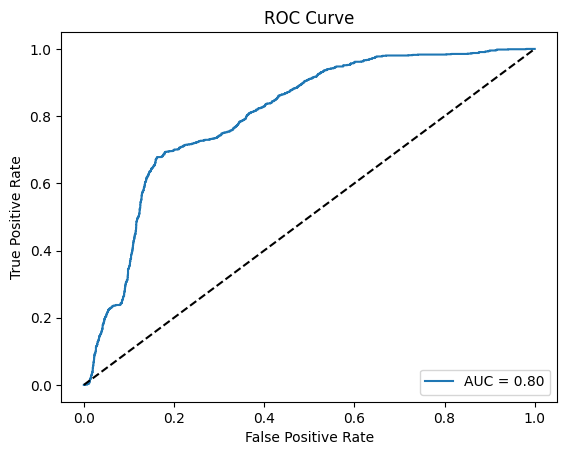

In [41]:
!pip install scikit-learn  # Install scikit-learn if you haven't already

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Assuming you have 'y_test' (true labels) and need to get 'y_pred_prob'

# Get predicted probabilities from your logistic regression model (lr)
y_pred_prob = lr.predict_proba(X_test)[:, 1]  # Probability of class 1 (churn)

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

# Calculate the AUC
auc = roc_auc_score(y_test, y_pred_prob)

# Plot the ROC curve
plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')  # Dashed diagonal line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

Pick any 5 classifiers below and follow the above instructions.

***2. Decision Tree***

In [42]:
# Import module
from sklearn.tree import DecisionTreeClassifier

# Create an instance
dt = DecisionTreeClassifier()

# Train the model
dt.fit(X_train, y_train)

# Predict the response for test dataset
dt_pred = dt.predict(X_test)

# Accuracy, Precision, Recall, F1
print("Accuracy:", metrics.accuracy_score(y_test, dt_pred))
print("Precision:", metrics.precision_score(y_test, dt_pred))
print("Recall:", metrics.recall_score(y_test, dt_pred))
print("F1 score:", metrics.f1_score(y_test, dt_pred))


Accuracy: 0.9728888888888889
Precision: 0.9294755877034359
Recall: 0.9589552238805971
F1 score: 0.9439853076216712


In [43]:
# Compute confusion matrix for Decision Tree
cnf_matrix_dt = confusion_matrix(y_test, dt_pred, labels=[1,0])
np.set_printoptions(precision=2)


Confusion matrix, without normalization
[[1028   44]
 [  78 3350]]


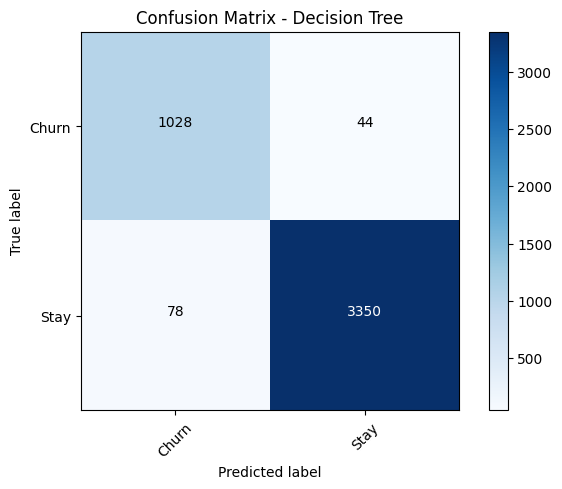

In [44]:
cm_dt = confusion_matrix(y_test, dt_pred, labels=[1, 0])
plot_confusion_matrix(cm=cm_dt,
                      classes=["Churn", "Stay"],
                      normalize=False,
                      title="Confusion Matrix - Decision Tree")


In [45]:
print(classification_report(y_test, dt_pred))


              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3428
           1       0.93      0.96      0.94      1072

    accuracy                           0.97      4500
   macro avg       0.96      0.97      0.96      4500
weighted avg       0.97      0.97      0.97      4500



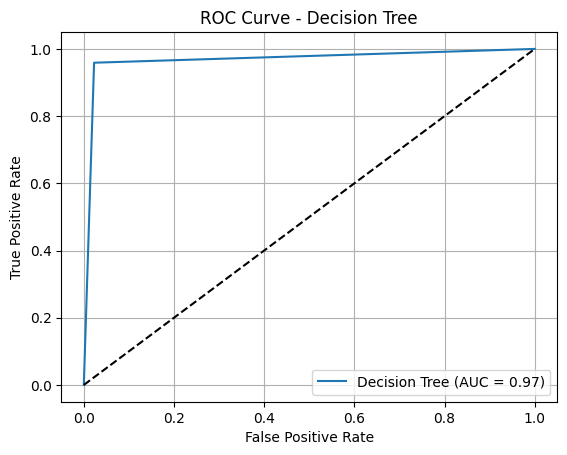

In [46]:
from sklearn.metrics import roc_curve, roc_auc_score

# Predict probabilities
y_prob_dt = dt.predict_proba(X_test)[:, 1]

# ROC curve
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)

# AUC score
auc_dt = roc_auc_score(y_test, y_prob_dt)

# Plot
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


***3. Random Forest***

In [47]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Accuracy:", metrics.accuracy_score(y_test, rf_pred))
print("Precision:", metrics.precision_score(y_test, rf_pred))
print("Recall:", metrics.recall_score(y_test, rf_pred))
print("F1 score:", metrics.f1_score(y_test, rf_pred))

Accuracy: 0.9877777777777778
Precision: 0.9922555663117134
Recall: 0.9561567164179104
F1 score: 0.9738717339667459


Confusion matrix, without normalization
[[1025   47]
 [   8 3420]]


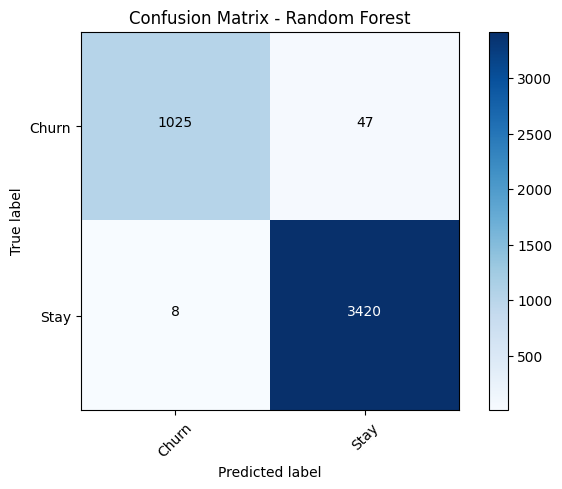

In [48]:
cm_rf = confusion_matrix(y_test, rf_pred, labels=[1, 0])
plot_confusion_matrix(cm=cm_rf,
                      classes=["Churn", "Stay"],
                      normalize=False,
                      title="Confusion Matrix - Random Forest")



In [50]:
# Compute confusion matrix for Random Forest
cnf_matrix_rf = confusion_matrix(y_test, rf_pred, labels=[1,0])
np.set_printoptions(precision=2)


In [49]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3428
           1       0.99      0.96      0.97      1072

    accuracy                           0.99      4500
   macro avg       0.99      0.98      0.98      4500
weighted avg       0.99      0.99      0.99      4500



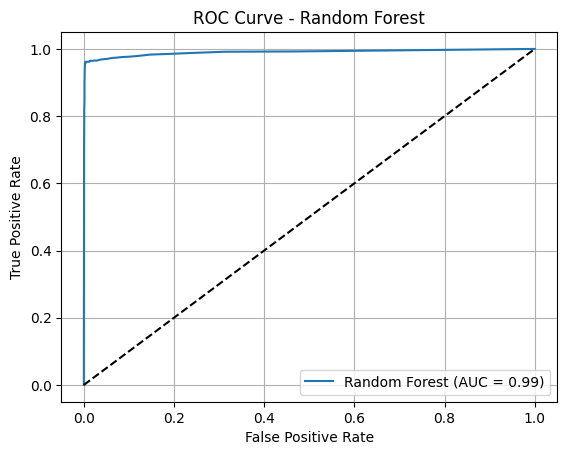

In [51]:
# Predict probabilities
y_prob_rf = rf.predict_proba(X_test)[:, 1]

# ROC curve
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# AUC score
auc_rf = roc_auc_score(y_test, y_prob_rf)

# Plot
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

***4.Gradient Boosting Classifier***

In [52]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

print("Accuracy:", metrics.accuracy_score(y_test, gb_pred))
print("Precision:", metrics.precision_score(y_test, gb_pred))
print("Recall:", metrics.recall_score(y_test, gb_pred))
print("F1 score:", metrics.f1_score(y_test, gb_pred))


Accuracy: 0.9715555555555555
Precision: 0.958252427184466
Recall: 0.9207089552238806
F1 score: 0.9391056137012369


Confusion matrix, without normalization
[[ 987   85]
 [  43 3385]]


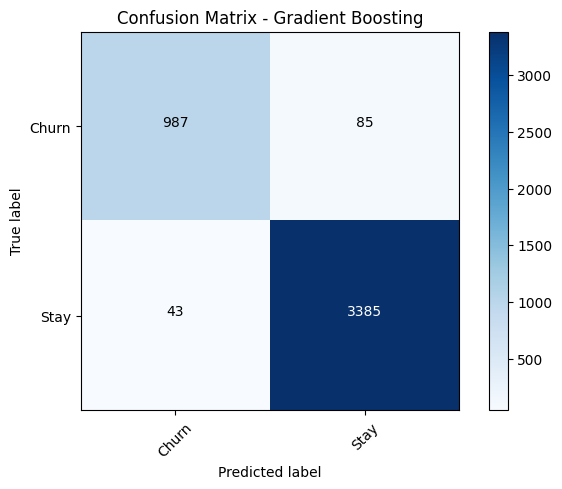

In [53]:
cm_gb = confusion_matrix(y_test, gb_pred, labels=[1, 0])
plot_confusion_matrix(cm=cm_gb,
                      classes=["Churn", "Stay"],
                      normalize=False,
                      title="Confusion Matrix - Gradient Boosting")


In [54]:
# Compute confusion matrix for Gradient Boosted Tree
cnf_matrix_gb = confusion_matrix(y_test, gb_pred, labels=[1,0])
np.set_printoptions(precision=2)

In [55]:
print(classification_report(y_test, gb_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98      3428
           1       0.96      0.92      0.94      1072

    accuracy                           0.97      4500
   macro avg       0.97      0.95      0.96      4500
weighted avg       0.97      0.97      0.97      4500



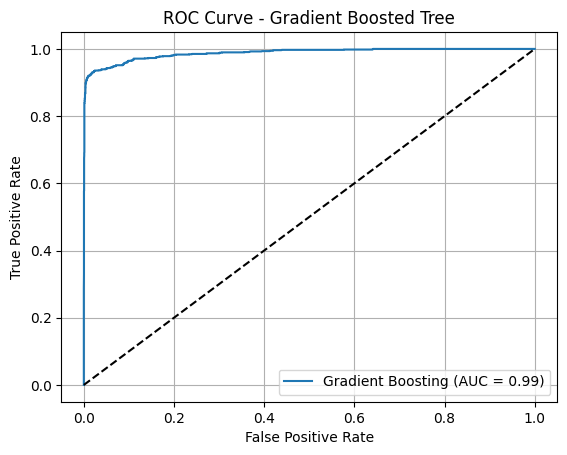

In [56]:
# Predict probabilities
y_prob_gb = gb.predict_proba(X_test)[:, 1]

# ROC curve
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_prob_gb)

# AUC score
auc_gb = roc_auc_score(y_test, y_prob_gb)

# Plot
plt.plot(fpr_gb, tpr_gb, label=f'Gradient Boosting (AUC = {auc_gb:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Gradient Boosted Tree')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

***5. Multilayer Perceptron***

In [57]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(max_iter=1000)
mlp.fit(X_train, y_train)
mlp_pred = mlp.predict(X_test)

print("Accuracy:", metrics.accuracy_score(y_test, mlp_pred))
print("Precision:", metrics.precision_score(y_test, mlp_pred))
print("Recall:", metrics.recall_score(y_test, mlp_pred))
print("F1 score:", metrics.f1_score(y_test, mlp_pred))


Accuracy: 0.9271111111111111
Precision: 0.8542857142857143
Recall: 0.8367537313432836
F1 score: 0.8454288407163054


Confusion matrix, without normalization
[[ 897  175]
 [ 153 3275]]


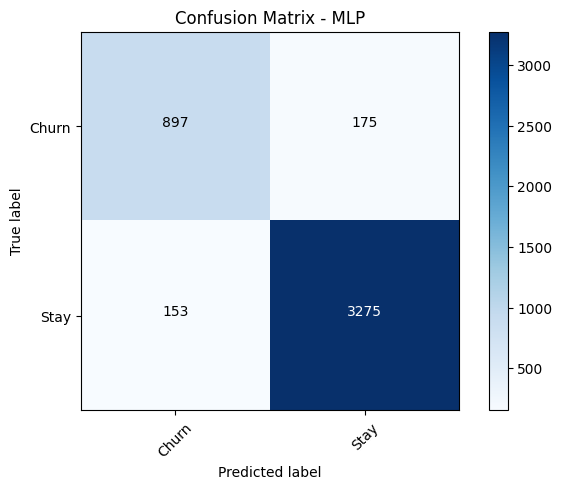

In [58]:
cm_mlp = confusion_matrix(y_test, mlp_pred, labels=[1, 0])
plot_confusion_matrix(cm=cm_mlp,
                      classes=["Churn", "Stay"],
                      normalize=False,
                      title="Confusion Matrix - MLP")


In [59]:
# Compute confusion matrix for Multilayer Perceptron
cnf_matrix_mlp = confusion_matrix(y_test, mlp_pred, labels=[1,0])
np.set_printoptions(precision=2)

In [60]:
print(classification_report(y_test, mlp_pred))

              precision    recall  f1-score   support

           0       0.95      0.96      0.95      3428
           1       0.85      0.84      0.85      1072

    accuracy                           0.93      4500
   macro avg       0.90      0.90      0.90      4500
weighted avg       0.93      0.93      0.93      4500



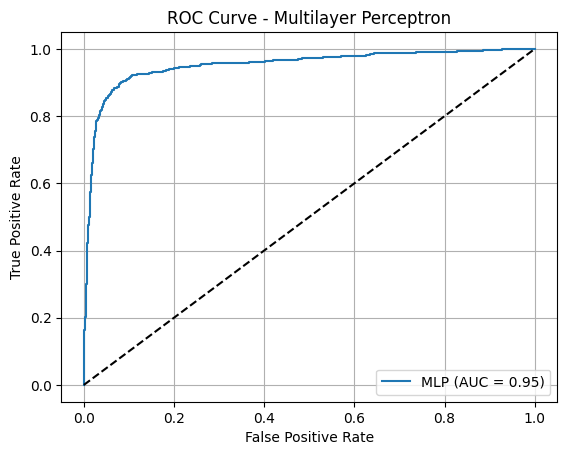

In [61]:
# Predict probabilities
y_prob_mlp = mlp.predict_proba(X_test)[:, 1]

# ROC curve
fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_prob_mlp)

# AUC score
auc_mlp = roc_auc_score(y_test, y_prob_mlp)

# Plot
plt.plot(fpr_mlp, tpr_mlp, label=f'MLP (AUC = {auc_mlp:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Multilayer Perceptron')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

***6. Support Vector Machine***

In [62]:
from sklearn.svm import SVC

svm = SVC()
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print("Accuracy:", metrics.accuracy_score(y_test, svm_pred))
print("Precision:", metrics.precision_score(y_test, svm_pred))
print("Recall:", metrics.recall_score(y_test, svm_pred))
print("F1 score:", metrics.f1_score(y_test, svm_pred))


Accuracy: 0.7846666666666666
Precision: 1.0
Recall: 0.0960820895522388
F1 score: 0.1753191489361702


Confusion matrix, without normalization
[[ 103  969]
 [   0 3428]]


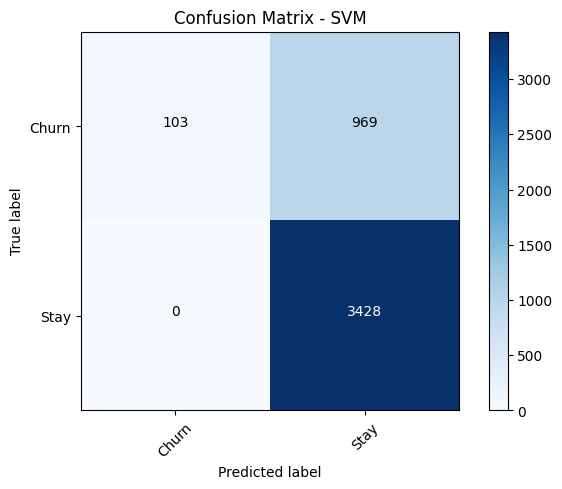

In [63]:
cm_svm = confusion_matrix(y_test, svm_pred, labels=[1, 0])
plot_confusion_matrix(cm=cm_svm,
                      classes=["Churn", "Stay"],
                      normalize=False,
                      title="Confusion Matrix - SVM")

In [64]:
# Compute confusion matrix for Support Vector Machine
cnf_matrix_svm = confusion_matrix(y_test, svm_pred, labels=[1,0])
np.set_printoptions(precision=2)

In [65]:
print(classification_report(y_test, svm_pred))

              precision    recall  f1-score   support

           0       0.78      1.00      0.88      3428
           1       1.00      0.10      0.18      1072

    accuracy                           0.78      4500
   macro avg       0.89      0.55      0.53      4500
weighted avg       0.83      0.78      0.71      4500



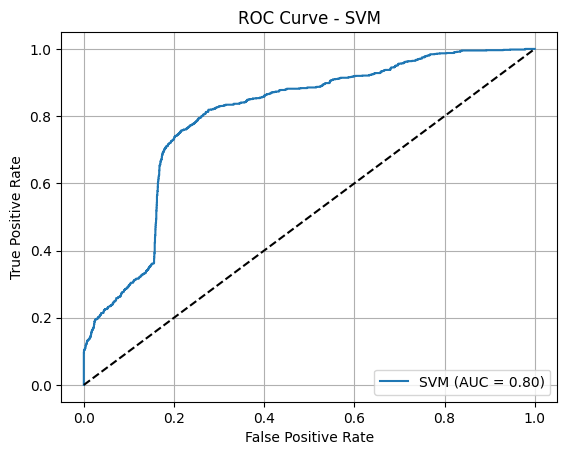

In [66]:
svm = SVC(probability=True)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)
# Fit the model to the training data
svm.fit(X_train, y_train) # this line was missing

# Predict probabilities
y_prob_svm = svm.predict_proba(X_test)[:, 1]

# ROC curve
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)

# AUC score
auc_svm = roc_auc_score(y_test, y_prob_svm)

# Plot
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {auc_svm:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - SVM')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [67]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Assuming you have already trained your models (lr, dt, rf, gb, mlp, svm)
# and have X_test and y_test

models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "MLP": mlp,
    "SVM": svm
}

results = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]  # Probability for positive class
    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "auc": roc_auc_score(y_test, y_prob)
    }

# Convert the results dictionary to a pandas DataFrame
results_df = pd.DataFrame.from_dict(results, orient='index')

# Print the results
print(results_df)

# Find the best model based on a chosen metric (e.g., AUC)
best_model_auc = results_df['auc'].idxmax()
print(f"\nBest model based on AUC: {best_model_auc}")

# Find the best model based on other metrics
best_model_accuracy = results_df['accuracy'].idxmax()
print(f"Best model based on accuracy: {best_model_accuracy}")

best_model_f1 = results_df['f1'].idxmax()
print(f"Best model based on F1-score: {best_model_f1}")


                     accuracy  precision    recall        f1       auc
Logistic Regression  0.760222   0.493230  0.237873  0.320957  0.802651
Decision Tree        0.972889   0.929476  0.958955  0.943985  0.968101
Random Forest        0.987778   0.992256  0.956157  0.973872  0.990192
Gradient Boosting    0.971556   0.958252  0.920709  0.939106  0.987675
MLP                  0.927111   0.854286  0.836754  0.845429  0.951640
SVM                  0.784667   1.000000  0.096082  0.175319  0.799324

Best model based on AUC: Random Forest
Best model based on accuracy: Random Forest
Best model based on F1-score: Random Forest


**Recommendation**


**Random Forest** is the most appropriate model for predicting employee churn because it demonstrates outstanding performance across all key metrics:

Accuracy: 0.988 – highest among all models, showing excellent overall correctness.

Precision: 0.992 – meaning very few false positives (non-churners wrongly predicted as churners).

Recall: 0.956 – crucial for churn prediction, as it captures 95.6% of actual churn cases, minimizing the risk of missing employees who will leave.

F1-score: 0.974 – best balance between precision and recall, ensuring both are optimized.

AUC: 0.991 – excellent class separation ability, confirming that the model can reliably distinguish between churners and non-churners.

Logistic Regression & SVM: Low recall (≤ 0.24 and 0.09) => miss most churners.

Decision Tree & Gradient Boosting: Good performance, but slightly lower F1/AUC than Random Forest.

MLP: Solid, but less effective than tree-based models overall.